In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
import random
from scipy.stats import qmc
from scipy.spatial import distance
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from scipy.optimize import minimize
from scipy.stats import norm
from pyDOE import lhs
import os

# Random Sampling Methods

In [3]:
seed = 42
np.random.seed(seed)
random.seed(seed)
os.environ["PYTHONHASHSEED"] = "42"  # For consistent hashing

def uniform_sampling(num_rows):
    return np.random.uniform(0, 1, (num_rows, 4))

def normal_sampling(num_rows):
    # Normal distribution samples are scaled to [0, 1] using the sigmoid function
    samples = np.random.normal(0, 1, (num_rows, 4))
    return 1 / (1 + np.exp(-samples))  # Sigmoid to map to [0, 1]

def stratified_sampling(num_rows):
    strata = np.linspace(0, 1, 9)[:-1] + np.diff(np.linspace(0, 1, 9)) / 2
    samples = np.array([[random.choice(strata) for _ in range(4)] for _ in range(num_rows)])
    return samples

def latin_hypercube_sampling(num_rows):
    # Using pyDOE for LHS, results are already in [0, 1] range
    return lhs(n=4, samples=num_rows)

def latin_hypercube_sum_constraint(num_rows, sum_constraint):
    lhs_samples = lhs(4, samples=num_rows, criterion='maximin')
    
    # Adjust each sample to meet the sum constraint
    for i in range(num_rows):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum
    
    return lhs_samples

def sobol_sampling(num_rows):
    sampler = qmc.Sobol(d=4, scramble=True)
    # Scale the samples to be in the range [0, 1]
    return qmc.scale(sampler.random_base2(m=int(np.log2(num_rows))), 0, 1)

def halton_sampling(num_rows):
    sampler = qmc.Halton(d=4, scramble=True)
    return qmc.scale(sampler.random(n=num_rows), 0, 1)

# Function to convert CMYK to RGB
def CMYK_to_RGB(c, m, y, k):
    R = (1 - c) * (1 - k)
    G = (1 - m) * (1 - k)
    B = (1 - y) * (1 - k)
    return np.array([R, G, B])

def RGB_to_CMYK(RGB_sample):
    Red = RGB_sample[0]/255
    Green = RGB_sample[1]/255
    Blue = RGB_sample[2]/255

    Black = min(1-Red,1-Green,1-Blue)
    Cyan = (1-Red-Black)/(1-Black)
    Magenta = (1-Green-Black)/(1-Black)
    Yellow  = (1-Blue-Black)/(1-Black) 

    return np.array([Cyan, Magenta, Yellow, Black])

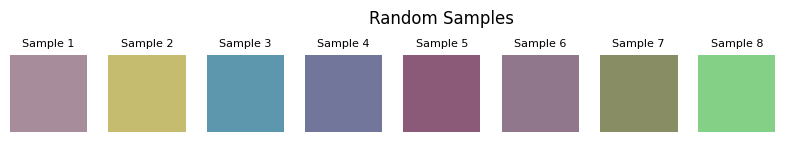

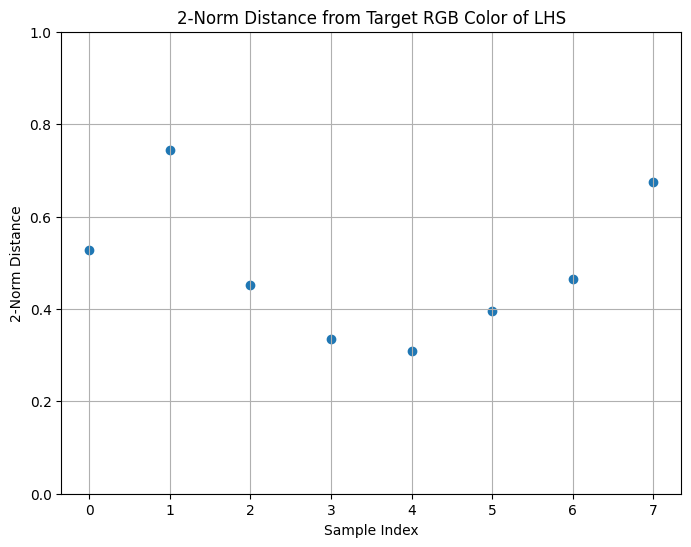

In [4]:
#target_color = (np.random.rand(3)*255).astype(int)  # Random target color
target_color = [75, 46, 131]
target_color_norm = np.array(target_color)/255
target_color_CMYK = RGB_to_CMYK(target_color)
target_string = ', '.join(str(x) for x in target_color)

# Generate a row of random CMYK samples
n_samples = 8
max_well_volume = 250

random_CMYK = (latin_hypercube_sum_constraint(n_samples, max_well_volume)/max_well_volume)

# Convert to RGB
random_RGB = np.array([CMYK_to_RGB(*cmyk) for cmyk in random_CMYK])

# Visualize the color combinations chosen by the algorithm over iterations.
if (n_samples+1) / 10 > 1:
    colors_per_row = 10  # Limit to 10 colors per row
else:
    colors_per_row = n_samples + 1

n_rows = (n_samples + colors_per_row) // colors_per_row  # Calculate total rows

plt.figure(figsize=(colors_per_row, n_rows * 1.4))
plt.suptitle('Random Samples')

for idx, rgb in enumerate(random_RGB):
    row = idx // colors_per_row
    col = idx % colors_per_row
    # Each color is displayed in its own grid
    plt.subplot(n_rows, colors_per_row, idx + 1)
    plt.imshow([[rgb]], extent=[0, 1, 0, 1])
    plt.axis("off")
    plt.title(f"Sample {idx + 1}", fontsize=8)

plt.tight_layout()

# Calculate the 2-norm distance for each sample color
def norm_error(norm_samples, target_color):
    return [np.linalg.norm(np.array(sample) - np.array(target_color)/255) for sample in norm_samples]

sample_distances = norm_error(random_RGB, target_color)

# Plot the distances
plt.figure(figsize=(8, 6))
plt.scatter(range(len(random_RGB)), sample_distances, marker='o')
plt.title('2-Norm Distance from Target RGB Color of LHS')
plt.xlabel('Sample Index')
plt.ylabel('2-Norm Distance')
plt.ylim(0,1)
plt.grid(True)
plt.show()

# Bayesian Optimization

In [5]:
# Optimization Parameters
hyperparameter = 0.01
threshold = 0.025
scaling_factor = 50

# Gaussian Process Regression model
kernel = C(constant_value=1, constant_value_bounds=(1e-3, 1e3)) * RBF(length_scale=1, length_scale_bounds=(1e-3, 1e3))
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, alpha=1e-4, normalize_y=False)

# Expected Improvement maximizes implicetly
def expected_improvement(X, X_sample, y_sample, model):
    """Return the expected improvement.
    Arguments
    mu     -- The predictive mean at the test points.
    sigma -- The predictive standard deviation at
             the test points.
    ymax  -- The maximum observed value (so far).
    """
    mu, sigma = model.predict(X, return_std=True)

    optiminal_sample = np.min(y_sample)
    
    with np.errstate(divide="ignore"):
        
        imp = mu - optiminal_sample - hyperparameter
        Z = imp / sigma
        ei = imp * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei.flatten()

# Function to propose the next sample point using Expected Improvement
def propose_location(acquisition, X_sample, y_sample, bounds, n_restarts=25):
    dim = X_sample.shape[1]

    def min_obj(x):
        return -acquisition(x.reshape(-1, dim), X_sample, y_sample, gp)

    # Starting points for optimization
    x0_list = np.random.uniform(0, 1, size=(n_restarts, dim))
    best_x, best_val = None, float("inf")
    for x0 in x0_list:
        res = minimize(min_obj, x0, bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x
    return best_x

def bayesian_optimization(random_samples, max_iterations, threshold = 5 / scaling_factor):

    # Initialize variables
    X = random_samples
    y = -np.linalg.norm(X - target_color_CMYK, axis=1)

    n_features = n_features = X[0].shape[0]  # CMYK components
    bounds = [(0, 1)] * n_features  # CMYK values are normalized between 0 and 1

    # Run Bayesian Optimization and visualize
    distances = []  # Track distances to the target
    X_samples = []  # Start with the first sample
    y_samples = []

    for i in range(max_iterations):
        gp.fit(X, y)  # Fit GP model
        
        # Propose the next sampling point
        X_next = propose_location(expected_improvement, X, y, bounds)
        
        # Evaluate the objective function for the new sample
        y_next = -np.linalg.norm(X_next - target_color_CMYK)
        distances.append(-y_next)  # Track the negative distance (closer to target)
        
        # Append the new sample to the dataset
        X = np.vstack((X, X_next))
        y = np.append(y, y_next)
        
        # Track the selected color
        X_samples.append(X_next)
        y_samples.append(y_next)

        # Check if the error is below the threshold
        if -y_next < threshold:
            print(f"Optimization stopped early: error below {threshold} at iteration {i + 1}")
            break

    return X_samples, y_samples

# Initialize Interactive Display

In [6]:
# Initialize storage for attempts
user_attempts = []
cmyk_attempts = []
distances = []
bo_distances = []

# Create interactive sliders
c_slider = widgets.FloatSlider(description="Cyan (%)", min=0, max=1, step=0.01, value=0.5, continuous_update=False)
m_slider = widgets.FloatSlider(description="Magenta (%)", min=0, max=1, step=0.01, value=0.5, continuous_update=False)
y_slider = widgets.FloatSlider(description="Yellow (%)", min=0, max=1, step=0.01, value=0.5, continuous_update=False)
k_slider = widgets.FloatSlider(description="Black (%)", min=0, max=1, step=0.01, value=0.5, continuous_update=False)
submit_button = widgets.Button(description="Submit")

# Title Widget
title = widgets.HTML("<h2>Color Optimization: Minimize Error to Reach Target Color</h2>")

# Output widgets for displaying colors and attempts
user_output = widgets.Output()
bo_output = widgets.Output()
random_output = widgets.Output()
attempt_tracker = widgets.IntText(value=0, description="Attempts:", disabled=True)
min_distance_display = widgets.FloatText(value=float("inf"), description="Best Guess:", disabled=True)
winner_display = widgets.HTML(value="<h2 style='text-align:center; font-size: 20px;'>Goal: < 5 Error before BO</h2>")

# Function to update the display on button click
def submit_color(_):
    global user_attempts, cmyk_attempts

    # Convert user CMYK input to RGB
    cmyk_values = (c_slider.value, m_slider.value, y_slider.value, k_slider.value)
    user_rgb = (CMYK_to_RGB(*cmyk_values)).astype(int)
    
    # Compute Euclidean distance from the target color
    distance = np.linalg.norm(cmyk_values - target_color_CMYK) 
    
    if np.isnan(distance) or np.isinf(distance):
        distance = 0.0
    
    # Store attempt data
    user_attempts.append(user_rgb)
    cmyk_attempts.append(cmyk_values)
    distances.append(distance*scaling_factor)

    # Calculate distances for BO guesses
    bo_distances.clear()
    for bo_guess in bo_guesses[:len(user_attempts)]:
        bo_distance = np.linalg.norm(bo_guess - target_color_CMYK)
        
        if np.isnan(bo_distance) or np.isinf(bo_distance):
            bo_distance = 0.0
            
        bo_distances.append(bo_distance*scaling_factor)

    # Get BO guess
    bo_comparison = bo_guesses[:len(user_attempts)]

    # Update attempt count
    attempt_tracker.value = len(user_attempts)

    # Update the minimum distance
    min_distance_display.value = round(min(distances), 1) if distances else None

    # Determine the winner
    if any(d < 5 for d in distances):
        winner_display.value = "<h2 style='text-align:center; font-size: 24px;'>User Wins!</h2>"
    elif any(d < 5 for d in bo_distances):
        winner_display.value = "<h2 style='text-align:center; font-size: 24px;'>BO Wins!</h2>"
    else:
        winner_display.value = "<h2 style='text-align:center; font-size: 20px;'>Goal: < 5 Error before BO</h2>"

    # Clear output and redraw
    with user_output:
        clear_output(wait=True)

        # Determine the number of rows needed for wrapping
        num_attempts = len(user_attempts)
        num_cols = 8  # Max colors per row
        num_rows = -(-num_attempts // num_cols)  # Ceiling division

        fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, num_rows * 2.1), constrained_layout=True)
        axes = np.array(axes).reshape(num_rows, num_cols)  # Ensure correct shape

        # Plot attempts with CMYK labels and distances
        for i, (rgb, cmyk, dist) in enumerate(zip(user_attempts, cmyk_attempts, distances)):
            row, col = divmod(i, num_cols)
            axes[row, col].imshow([[rgb]])
            axes[row, col].set_title(
                f"C:{cmyk[0]:.2f}% M:{cmyk[1]:.2f}%\nY:{cmyk[2]:.2f}% K:{cmyk[3]:.2f}%\nError:{dist:.1f}", fontsize=7)
            axes[row, col].axis("off")

        # Hide unused subplots
        for i in range(num_attempts, num_rows * num_cols):
            row, col = divmod(i, num_cols)
            axes[row, col].axis("off")

        plt.suptitle("User Attempts", fontsize=12)
        plt.show()

    with bo_output:
        clear_output(wait=True)
        num_bo_guesses = len(bo_comparison)
        num_cols = 8
        num_rows = -(-num_bo_guesses // num_cols)

        fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, num_rows * 2.1), constrained_layout=True)
        axes = np.array(axes).reshape(num_rows, num_cols)

        # Plot BO guesses
        for i, (bo_guess, dist) in enumerate(zip(bo_comparison, bo_distances)):
            row, col = divmod(i, num_cols)
            bo_rgb = CMYK_to_RGB(*bo_guess)
            bo_rgb_255 = (bo_rgb * 255).astype(int)
            axes[row, col].imshow([[bo_rgb]])
            axes[row, col].set_title(f"R:{bo_rgb_255[0]} G:{bo_rgb_255[1]}\n B:{bo_rgb_255[2]}\nError:{dist:.1f}", fontsize=7)
            axes[row, col].axis("off")

        # Hide extra subplots
        for i in range(num_bo_guesses, num_rows * num_cols):
            row, col = divmod(i, num_cols)
            axes[row, col].axis("off")

        plt.suptitle("Bayesian Optimization (BO) Attempts", fontsize=12)
        plt.show()

# Initial BO guesses before first user submission
max_iterations = 30
bo_guesses, output = bayesian_optimization(random_CMYK, max_iterations)  # Initially generate 10 guesses from BO

# Attach the button click event
submit_button.on_click(submit_color)

# Display target color and attempt tracker immediately
target_display = widgets.Output()
with target_display:
    fig, ax = plt.subplots(figsize=(2, 2))
    ax.imshow([[target_color]])
    ax.axis("off")
    plt.title("Target Color (" + target_string + ")")
    plt.show()

# Layout: Sliders + Target Color + Attempt Tracker + Min Distance in the same row
control_panel = widgets.HBox([
    widgets.VBox([c_slider, m_slider, y_slider, k_slider, submit_button]), 
    target_display, 
    widgets.VBox([attempt_tracker, min_distance_display,winner_display])
])

# Show the initial random sampling row (remains visible)
with random_output:
    fig, axes = plt.subplots(1, 8, figsize=(15, 2))
    for i, (rgb, cmyk) in enumerate(zip(random_RGB, random_CMYK)):
        axes[i].imshow([[rgb]])
        axes[i].set_title(f"C:{cmyk[0]:.2f}% M:{cmyk[1]:.2f}% \n Y:{cmyk[2]:.2f}% K:{cmyk[3]:.2f}%", fontsize=7)
        axes[i].axis("off")

    plt.suptitle("Random Samples", fontsize=12)
    plt.tight_layout()
    plt.show()

c:\Users\Austin\AppData\Local\Programs\Python\Python313\Lib\site-packages\jupyter_client\session.py:721: UserWarning: Message serialization failed with:
Out of range float values are not JSON compliant: inf
Supporting this message is deprecated in jupyter-client 7, please make sure your message is JSON-compliant
  content = self.pack(content)


Optimization stopped early: error below 0.1 at iteration 5


# Color Optimization Demo

In [7]:
# Display everything
display(widgets.VBox([title, control_panel, user_output, random_output, bo_output]))

In [ ]:
X = bo_guesses
y = output
# Display final results
optimal_rgb = X[np.argmax(y)]
optimal_cmyk = RGB_to_CMYK(optimal_rgb)

print("Closest distance to target color:", -np.max(y))
print("Optimal mixture:", optimal_rgb)
print("Target mixture:", RGB_to_CMYK(target_color))

# Test GP Plot

In [ ]:
# Initialize storage for attempts
user_attempts = []
cmyk_attempts = []
bo_guesses = []
user_distances = []
bo_distances = []
X_samples = []
y_samples = []
threshold = 5

# Initialize variables
n_features = 4  # CMYK components
bounds = [(0, 1)] * n_features  # CMYK values are normalized between 0 and 1

X = random_CMYK
y = -np.linalg.norm(X - target_color_CMYK, axis=1)

# Gaussian Process Regression model
kernel = C(constant_value=1, constant_value_bounds=(1e-3, 1e3)) * RBF(length_scale=1, length_scale_bounds=(1e-3, 1e3))
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, alpha=1e-4, normalize_y=False)

# Create interactive sliders
c_slider = widgets.FloatSlider(description="Cyan (%)", min=0, max=1, step=0.01, value=0.5, continuous_update=False)
m_slider = widgets.FloatSlider(description="Magenta (%)", min=0, max=1, step=0.01, value=0.5, continuous_update=False)
y_slider = widgets.FloatSlider(description="Yellow (%)", min=0, max=1, step=0.01, value=0.5, continuous_update=False)
k_slider = widgets.FloatSlider(description="Black (%)", min=0, max=1, step=0.01, value=0.5, continuous_update=False)
submit_button = widgets.Button(description="Submit")

# Title Widget
title = widgets.HTML("<h2>Color Optimization: Minimize Error to Reach Target Color</h2>")

# Output widgets for displaying colors and attempts
user_output = widgets.Output()
bo_output = widgets.Output()
random_output = widgets.Output()
attempt_tracker = widgets.IntText(value=0, description="Attempts:", disabled=True)
min_distance_display = widgets.FloatText(value=float("inf"), description="Best Guess:", disabled=True)
winner_display = widgets.HTML(value="<h2 style='text-align:center; font-size: 20px;'>Goal: < 5% Error before BO</h2>")
error_output = widgets.Output()
gp_plot_output = widgets.Output()
ei_plot_output = widgets.Output()

In [ ]:
# Function to update the display on button click
def submit_color(_):
    global user_attempts, cmyk_attempts, X, y, bo_guesses, bo_distances, gp

    # Convert user CMYK input to RGB
    cmyk_values = (c_slider.value, m_slider.value, y_slider.value, k_slider.value)
    user_rgb = (CMYK_to_RGB(*cmyk_values) * 255).astype(int)
    
    # Compute Euclidean distance from the target color
    distance = np.linalg.norm(cmyk_values - target_color_CMYK) * scaling_factor
    
    if np.isnan(distance) or np.isinf(distance):
        distance = 0.0
    
    # Store attempt data
    user_attempts.append(user_rgb)
    cmyk_attempts.append(cmyk_values)
    user_distances.append(distance)

    # Update attempt count
    attempt_tracker.value = len(user_attempts)

    # Update the minimum distance
    min_distance_display.value = round(min(user_distances), 1) if user_distances else None

    # Only run BO if the best distance is greater than the threshold
    if not bo_distances or min(bo_distances) > threshold:
        # Update GP model
        gp.fit(X, y)  # Fit GP model to the current data

        # Propose the next sampling point based on Bayesian Optimization
        X_next = propose_location(expected_improvement, X, y, bounds)
        y_next = -np.linalg.norm(X_next - target_color_CMYK)  # Compute the negative distance
        
        # Append the new sample to the dataset
        X_samples.append(X_next)
        y_samples.append(y_next)

        X = np.vstack((X, X_next))
        y = np.append(y, y_next)
        
        # Track the selected color
        bo_rgb = (CMYK_to_RGB(X_next[0],X_next[1],X_next[2],X_next[3])*255).astype(int)
        bo_distances.append(np.linalg.norm(X_next - target_color_CMYK)*scaling_factor) # Track the negative distance (closer to target)
        bo_guesses.append(X_next)

    # Determine the winner
    if any(d < 5 for d in user_distances):
        winner_display.value = "<h2 style='text-align:center; font-size: 24px;'>User Wins!</h2>"
    elif any(d < 5 for d in bo_distances):
        winner_display.value = "<h2 style='text-align:center; font-size: 24px;'>BO Wins!</h2>"
    else:
        winner_display.value = "<h2 style='text-align:center; font-size: 20px;'>Goal: < 5% Error before BO</h2>"

    # Clear output and redraw user attempts
    with user_output:
        clear_output(wait=True)

        # Determine the number of rows needed for wrapping
        num_attempts = len(user_attempts)
        num_cols = 8  # Max colors per row
        num_rows = -(-num_attempts // num_cols)  # Ceiling division

        fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, num_rows * 2.1), constrained_layout=True)
        axes = np.array(axes).reshape(num_rows, num_cols)  # Ensure correct shape

        # Plot attempts with CMYK labels and distances
        for i, (rgb, cmyk, dist) in enumerate(zip(user_attempts, cmyk_attempts, user_distances)):
            row, col = divmod(i, num_cols)
            axes[row, col].imshow([[rgb]])
            axes[row, col].set_title(
                f"C:{cmyk[0]:.2f}% M:{cmyk[1]:.2f}%\nY:{cmyk[2]:.2f}% K:{cmyk[3]:.2f}%\nError:{dist:.1f}%", fontsize=7)
            axes[row, col].axis("off")

        # Hide unused subplots
        for i in range(num_attempts, num_rows * num_cols):
            row, col = divmod(i, num_cols)
            axes[row, col].axis("off")

        plt.suptitle("User Attempts", fontsize=12)
        plt.show()

    # Clear output and redraw BO guesses
    with bo_output:
        clear_output(wait=True)
        
        num_bo_guesses = len(bo_guesses)
        num_cols = 8
        num_rows = -(-num_bo_guesses // num_cols)

        fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, num_rows * 2.1), constrained_layout=True)
        axes = np.array(axes).reshape(num_rows, num_cols)

        # Plot BO guesses
        for i, (bo_guess, dist) in enumerate(zip(bo_guesses, bo_distances)):
            row, col = divmod(i, num_cols)
            bo_rgb = CMYK_to_RGB(*bo_guess)
            bo_rgb_255 = (bo_rgb * 255).astype(int)
            axes[row, col].imshow([[bo_rgb]])
            axes[row, col].set_title(f"R:{bo_rgb_255[0]} G:{bo_rgb_255[1]}\n B:{bo_rgb_255[2]}\nError:{dist:.1f}%", fontsize=7)
            axes[row, col].axis("off")

        # Hide extra subplots
        for i in range(num_bo_guesses, num_rows * num_cols):
            row, col = divmod(i, num_cols)
            axes[row, col].axis("off")

        plt.suptitle("BO Attempts", fontsize=12)
        plt.show()

    # Plot convergence
    with error_output:
        clear_output(wait=True)  # Clear previous output before displaying the new plot
    # Plot the convergence
        plt.figure(figsize=(8, 6))
        plt.plot(range(1, len(bo_distances) + 1), bo_distances, marker='o', linestyle='-', color='b')
        plt.title('Convergence of Bayesian Optimization')
        plt.xlabel('Iteration')
        plt.ylabel('Distance to Target Color')
        plt.grid(True)
        plt.show()

    # Plot the training data, predicted mean, and confidence interval
    with gp_plot_output:
        clear_output(wait=True)

        n_features = X_samples[0].shape[0]  # Should be 4 for CMYK
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        for i in range(n_features):
            # Fix other features to their mean values from training data
            #fixed_values = np.mean(X_samples, axis=0)
            fixed_values = target_color_CMYK.copy()

            # Generate a grid for the ith feature
            X_grid = np.linspace(0, 1, 100).reshape(-1, 1)
            X_full_grid = np.tile(fixed_values, (100, 1))
            X_full_grid[:, i] = X_grid.ravel()  # Vary only the ith feature

            # Predict the mean and standard deviation
            mu, sigma = gp.predict(X_full_grid, return_std=True)

            # Convert lists to numpy arrays if necessary
            mu = np.array(mu)
            sigma = np.array(sigma)
            y_samples_arr = np.array(y_samples)

            # Calculate the true objective (2-norm distance to target color)
            true_objective = [np.linalg.norm(cmyk - target_color_CMYK) for cmyk in X_full_grid]

            ax = axes[i // 2, i % 2]

            # Plot the true objective function
            ax.plot(X_grid, true_objective, color='black', label='True Objective')

            # Plot the predicted mean
            ax.plot(X_grid, -mu, color='blue', linestyle='--', label='Predicted Mean')
            ax.fill_between(
                X_grid.ravel(), -mu - 1.96 * sigma, -mu + 1.96 * sigma,
                color='blue', alpha=0.2, label='95% Confidence Interval'
            )

            # Plot the training data for this feature
            ax.scatter([x[i] for x in X_samples], -y_samples_arr, color='red', zorder=10, label='Training Data')

            ax.scatter(X[-1][i], -y[-1], color='green', zorder=10, label='Next Sample')

            # Labels and title
            ax.set_title(f"GP Regression for Feature {['C', 'M', 'Y', 'K'][i]}", fontsize=14)
            ax.set_xlabel(f"{['C', 'M', 'Y', 'K'][i]} Value", fontsize=12)
            ax.set_ylabel("Distance to Target", fontsize=12)
            ax.legend()

        plt.tight_layout()
        plt.show()

    # Plot expected improvement
    with ei_plot_output:
        clear_output(wait=True)

        n_features = len(X_samples[0])  # Number of features (should be 4 for CMYK)
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        for i, ax in enumerate(axes.flatten()):
            # Fix other features to their mean values from training data
            fixed_values = np.mean(X_samples, axis=0)

            # Generate a grid for the ith feature
            X_grid = np.linspace(0, 1, 100).reshape(-1, 1)
            X_full_grid = np.tile(fixed_values, (100, 1))
            X_full_grid[:, i] = X_grid.ravel()  # Vary only the ith featur

            # Compute EI
            ei = expected_improvement(X_full_grid, np.array(X_samples), np.array(y_samples), gp)

            # Find the next sampling point (max EI)
            next_index = np.argmax(ei)
            next_x = X_grid[next_index]
            next_ei = ei[next_index]

            # Plot EI curve
            ax.plot(X_grid, ei, color='purple', linestyle='-', label='Expected Improvement')

            # Highlight next sampling point
            ax.scatter(next_x, next_ei, color='red', s=100, marker='o', label='Next Sample Point')
            ax.axvline(next_x, color='red', linestyle='--', alpha=0.5)

            # Titles and labels
            ax.set_title(f"Expected Improvement for Feature {['C', 'M', 'Y', 'K'][i]}")
            ax.set_xlabel(f"{['C', 'M', 'Y', 'K'][i]} Value")
            ax.set_ylabel("Expected Improvement")
            ax.legend()
            ax.grid(True)

        plt.tight_layout()
        plt.show()
    
# Attach the button click event
submit_button.on_click(submit_color)

# Display target color and attempt tracker immediately
target_display = widgets.Output()
with target_display:
    fig, ax = plt.subplots(figsize=(2, 2))
    ax.imshow([[target_color]])
    ax.axis("off")
    plt.title("Target Color (" + target_string + ")")
    plt.show()

# Layout: Sliders + Target Color + Attempt Tracker + Min Distance in the same row
control_panel = widgets.HBox([widgets.VBox([c_slider, m_slider, y_slider, k_slider, submit_button]), 
                              target_display, 
                              widgets.VBox([attempt_tracker, min_distance_display, winner_display])])

# Show the initial random sampling row (remains visible)
with random_output:
    fig, axes = plt.subplots(1, 8, figsize=(15, 2))
    for i, (rgb, cmyk) in enumerate(zip(random_RGB, random_CMYK)):
        axes[i].imshow([[rgb]])
        axes[i].set_title(f"C:{cmyk[0]:.2f}% M:{cmyk[1]:.2f}% \n Y:{cmyk[2]:.2f}% K:{cmyk[3]:.2f}%", fontsize=7)
        axes[i].axis("off")

    plt.suptitle("Random Samples", fontsize=12)
    plt.tight_layout()
    plt.show()

In [ ]:
# Display everything
display(widgets.VBox([title, control_panel, user_output, bo_output, random_output, error_output, gp_plot_output, ei_plot_output]))